# 14. Tutorial 14

**Course:** High Switching Frequency Power Converters

## 14.1 A design notebook

A design notebook keeps specification, component data, models and results in one place, so that every number of the design package can be recomputed. Example: the TCM buck of brief B1 from Tutorials 6 to 8 ($48~\mathrm{V} \to 12~\mathrm{V}$, $100~\mathrm{W}$, $L = 225~\mathrm{nH}$, $N = 3$, $A_\mathrm{e} = 20~\mathrm{mm^2}$, $V_\mathrm{e} = 0.6~\mathrm{cm^3}$, Fair-Rite 67, two layers of $70~\mu\mathrm{m}$ copper with $R_\mathrm{dc} = 2~\mathrm{m\Omega}$, GaN transistors with $R_\mathrm{DS(on)} = 7~\mathrm{m\Omega}$, $Q_\mathrm{G} = 5.9~\mathrm{nC}$ at $5~\mathrm{V}$ and $C_\mathrm{oss}(v) = C_0/\sqrt{1 + v/V_\mathrm{j}}$ with $C_0 = 443~\mathrm{pF}$, $V_\mathrm{j} = 5~\mathrm{V}$).

14.1.1 Import necessary modules (numpy as np, pandas as pd, matplotlib.pyplot as plt) and collect the specification and the component data in dictionaries. Mark every assumed value.

14.1.2 Create a function `losses(f, s, N)` that returns the loss components of the TCM buck at full load for the full-load frequency $f$, a core scaled in all dimensions by $s$ and $N$ turns: conduction, turn-off ($I_\mathrm{pk}^2t_\mathrm{f}^2/(24\cdot2C_\mathrm{o(tr)})$ per cycle), gate drive, core (Steinmetz parameters of Fair-Rite 67 interpolated between 2 and $20~\mathrm{MHz}$, iGSE factor for $D = 0.25$) and winding (Dowell for two layers, DC part and harmonics). Print the loss budget of the design of Tutorials 6 to 8 ($f = 2~\mathrm{MHz}$, $s = 1$, $N = 3$) and compare with the earlier results.


In [1]:
# Subtask 14.1.1 Import necessary modules, specification and component data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

spec = dict(Vin=48.0, Vo=12.0, P=100.0)
spec['Io'] = spec['P'] / spec['Vo']
spec['D'] = spec['Vo'] / spec['Vin']

gan = dict(Ron=7e-3, QG=5.9e-9, Vdr=5.0, C0=443e-12, Vj=5.0,
           tf=1e-9)                                  # tf: ASSUMED channel fall time at turn-off
tcm = dict(Ineg=1.67)                               # negative current for ZVS (Tutorial 8)
core_ref = dict(Ae=20e-6, Ve=0.6e-6)                # reference core of Tutorial 6 (s = 1)
wind_ref = dict(Rdc=2e-3, N=3, h=70e-6, M=2)        # reference winding of Tutorial 7
# Fair-Rite 67, Hanson et al. 2016 (Tutorial 6): Pv = k * B^beta, Pv in mW/cm3, B in mT
fr67 = pd.DataFrame(dict(f=[2e6, 5e6, 10e6, 20e6], k=[0.10, 0.69, 2.09, 10.95], beta=[2.44, 2.20, 2.08, 1.99]))
alpha_igse = 1.5                                    # ASSUMED frequency exponent for the iGSE (Tutorial 6)
limits = dict(Bpk=0.150, pv=1000.0)                 # ASSUMED: peak flux density (T), core loss density (mW/cm3)


def qoss(V, C0=gan['C0'], Vj=gan['Vj']):
    return 2 * C0 * Vj * (np.sqrt(1 + V / Vj) - 1)


Co_tr = qoss(spec['Vin']) / spec['Vin']
print(f"Io = {spec['Io']:.2f} A, D = {spec['D']:.2f}, Qoss(48 V) = {qoss(spec['Vin'])*1e9:.2f} nC, Co(tr) = {Co_tr*1e12:.0f} pF")


Io = 8.33 A, D = 0.25, Qoss(48 V) = 9.99 nC, Co(tr) = 208 pF


In [2]:
# Subtask 14.1.2 Loss models from the tutorials
def steinmetz(f):
    """k and beta of Fair-Rite 67, log-log interpolation between 2 and 20 MHz."""
    lf = np.log(f)
    k = np.exp(np.interp(lf, np.log(fr67.f), np.log(fr67.k)))
    beta = np.interp(lf, np.log(fr67.f), fr67.beta)
    return k, beta


def igse_factor(D, a=alpha_igse):
    """Ratio of the iGSE loss of a triangular flux to the sinusoidal loss of the same peak (Tutorial 6)."""
    th = np.linspace(0, 2 * np.pi, 20001)
    integral = np.trapezoid(np.abs(np.cos(th))**a, th)
    return 2**a * (D**(1 - a) + (1 - D)**(1 - a)) / ((2 * np.pi)**(a - 1) * integral)


def dowell(phi, M):
    G1 = (np.sinh(2 * phi) + np.sin(2 * phi)) / (np.cosh(2 * phi) - np.cos(2 * phi))
    G2 = (np.sinh(phi) * np.cos(phi) + np.cosh(phi) * np.sin(phi)) / (np.cosh(2 * phi) - np.cos(2 * phi))
    return phi * (G1 + 2 / 3 * (M**2 - 1) * (G1 - 2 * G2))


def losses(f, s=1.0, N=3, k_core=1.0, k_ron=1.0, k_rw=1.0, k_tf=1.0):
    Vin, Vo, Io, D = spec['Vin'], spec['Vo'], spec['Io'], spec['D']
    Ineg = tcm['Ineg']
    L = Vo * (1 - D) / (2 * f * (Io + Ineg))           # TCM: full-load frequency f
    di = 2 * (Io + Ineg)
    ipk = Io + di / 2
    irms2 = Io**2 + di**2 / 12
    out = {}
    out['conduction'] = irms2 * gan['Ron'] * k_ron
    out['turn-off'] = ipk**2 * (gan['tf'] * k_tf)**2 / (24 * 2 * Co_tr) * f
    out['gate drive'] = 2 * gan['QG'] * gan['Vdr'] * f
    Ae, Ve = core_ref['Ae'] * s**2, core_ref['Ve'] * s**3
    dB = (Vin - Vo) * D / f / (N * Ae)
    k, beta = steinmetz(f)
    pv = k * (dB / 2 * 1e3)**beta * igse_factor(D) * k_core          # mW/cm3
    out['core'] = pv * Ve * 1e3                                       # W (Ve in m3 -> cm3: *1e6, mW -> W: *1e-3)
    Rdc = wind_ref['Rdc'] * (N / wind_ref['N'])**2 / s * k_rw
    delta = 75.7e-6 / np.sqrt(f / 1e6)                                # skin depth of copper at 100 C, as in Tutorial 7
    h = wind_ref['h'] * s
    n = np.arange(1, 40)
    i_n = di * np.abs(np.sin(n * np.pi * D)) / (np.pi**2 * n**2 * D * (1 - D))   # Tutorial 7
    Fr = dowell(h / delta * np.sqrt(n), wind_ref['M'])
    out['winding'] = Rdc * (Io**2 + np.sum((i_n / np.sqrt(2))**2 * Fr))
    Bpk = (L * Io / (N * Ae)) + dB / 2
    return out, dict(L=L, dB=dB, Bpk=Bpk, pv=pv, Rdc=Rdc, ipk=ipk, irms=np.sqrt(irms2))


ref, info = losses(2e6, 1.0, 3)
for key, val in ref.items():
    print(f"{key:12s} {val:6.3f} W")
Ptot = sum(ref.values())
print(f"total {Ptot:.2f} W, efficiency {spec['P']/(spec['P']+Ptot)*100:.2f} %")
print(f"L = {info['L']*1e9:.0f} nH, dB = {info['dB']*1e3:.0f} mT, Bpk = {info['Bpk']*1e3:.0f} mT, pv = {info['pv']:.0f} mW/cm3, "
      f"iGSE factor {igse_factor(spec['D']):.3f}, Fr check (phi = 1.308, M = 2): {dowell(1.308, 2):.2f}")


conduction    0.720 W
turn-off      0.067 W
gate drive    0.118 W
core          0.423 W
winding       0.301 W
total 1.63 W, efficiency 98.40 %
L = 225 nH, dB = 75 mT, Bpk = 69 mT, pv = 705 mW/cm3, iGSE factor 1.018, Fr check (phi = 1.308, M = 2): 2.11


### 14.1 Solution

The template reproduces the earlier results: conduction $0.72~\mathrm{W}$ (Tutorial 8), core $0.42~\mathrm{W}$ at $705~\mathrm{mW/cm^3}$ (Tutorial 6), winding $0.30~\mathrm{W}$ (Tutorial 7, now with all harmonics), plus turn-off $0.07~\mathrm{W}$ and gate drive $0.12~\mathrm{W}$: $1.63~\mathrm{W}$ and $98.40~\%$ at full load. Every number of the design package should come from such a function call, so that a changed input changes every table.


## 14.2 Efficiency versus power density

14.2.1 Create a function `volume(f, s, N, P_loss)` for the boxed volume: inductor (twice the core volume), output and input capacitors from their ripple requirements, heat sink from the cooling system performance index ($\mathrm{CSPI} = 20~\mathrm{W/(dm^3\,K)}$, $40~\mathrm{K}$) and a fixed volume for board and transistors. Sweep $f = 2 \ldots 8~\mathrm{MHz}$, $s = 0.6 \ldots 1.6$ and $N = 2 \ldots 5$; reject designs with a peak flux density above $150~\mathrm{mT}$ or a core loss density above $1~\mathrm{W/cm^3}$.

14.2.2 Extract the Pareto front (highest efficiency for each power density) and plot all feasible designs, the front and the design of Tutorials 6 to 8. Which variables change along the front?


In [3]:
# Subtask 14.2.1 Volume model and sweep
cap = dict(dV_out=0.12, dV_in=0.5, mm3_per_uF=2.0)    # ASSUMED: ripple targets, MLCC volume per effective uF
cooling = dict(CSPI=20.0, dT=40.0, V_fixed=2.0)        # ASSUMED: W/(dm3 K), K, cm3 for board and transistors


def volume(f, s, N, Ploss):
    Io, D = spec['Io'], spec['D']
    di = 2 * (Io + tcm['Ineg'])
    C_out = di / (8 * f * cap['dV_out'])
    C_in = Io * D * (1 - D) / (f * cap['dV_in'])
    V_L = 2 * core_ref['Ve'] * s**3 * 1e6                    # cm3
    V_C = (C_out + C_in) * 1e6 * cap['mm3_per_uF'] * 1e-3      # cm3
    V_hs = Ploss / (cooling['CSPI'] * cooling['dT']) * 1e3    # cm3
    return V_L + V_C + V_hs + cooling['V_fixed']


rows = []
for f in np.geomspace(2e6, 8e6, 25):
    for s in np.linspace(0.6, 1.6, 21):
        for N in (2, 3, 4, 5):
            lo, inf = losses(f, s, N)
            Pl = sum(lo.values())
            ok = (inf['Bpk'] <= limits['Bpk']) and (inf['pv'] <= limits['pv'])
            rows.append(dict(f=f, s=s, N=N, Ploss=Pl, eta=spec['P'] / (spec['P'] + Pl),
                             rho=spec['P'] / volume(f, s, N, Pl), Bpk=inf['Bpk'], pv=inf['pv'], ok=ok))
sweep = pd.DataFrame(rows)
feas = sweep[sweep.ok].reset_index(drop=True)
print(f"{len(sweep)} designs, {len(feas)} feasible")


2100 designs, 1724 feasible


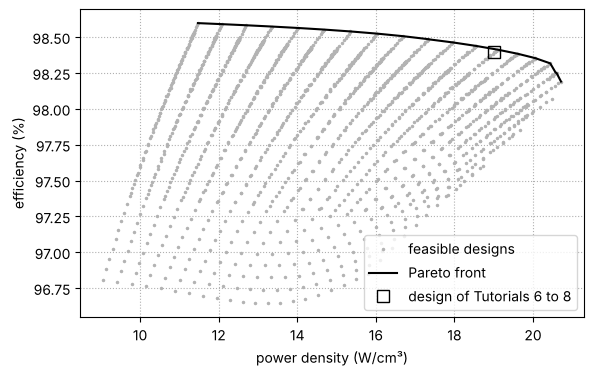

           f    s  N  Ploss     eta        rho   Bpk         pv
55  2.00 MHz 1.60  3 1.42 W 98.60 % 11.5 W/cm3 27 mT  71 mW/cm3
47  2.00 MHz 1.50  3 1.44 W 98.58 % 12.7 W/cm3 31 mT  98 mW/cm3
39  2.00 MHz 1.40  3 1.46 W 98.56 % 14.0 W/cm3 35 mT 137 mW/cm3
31  2.00 MHz 1.30  3 1.48 W 98.54 % 15.4 W/cm3 41 mT 196 mW/cm3
23  2.00 MHz 1.20  3 1.52 W 98.51 % 16.7 W/cm3 48 mT 290 mW/cm3
78  2.12 MHz 1.15  3 1.54 W 98.49 % 17.3 W/cm3 49 mT 333 mW/cm3
131 2.24 MHz 1.05  3 1.59 W 98.44 % 18.5 W/cm3 56 mT 483 mW/cm3
248 2.52 MHz 0.95  3 1.64 W 98.38 % 19.6 W/cm3 60 mT 679 mW/cm3
434 3.00 MHz 0.85  3 1.71 W 98.32 % 20.4 W/cm3 63 mT 937 mW/cm3
700 3.78 MHz 0.80  3 1.78 W 98.25 % 20.6 W/cm3 57 mT 958 mW/cm3


In [4]:
# Subtask 14.2.2 Pareto front
order = feas.sort_values('rho', ascending=False)
front, best = [], -1
for i, r in order.iterrows():
    if r.eta > best:
        front.append(i)
        best = r.eta
pf = feas.loc[front].sort_values('rho')
lo_ref = sum(losses(2e6, 1.0, 3)[0].values())
plt.figure(figsize=(6.5, 4))
plt.plot(feas.rho, feas.eta * 100, '.', color='0.7', ms=3, label='feasible designs')
plt.plot(pf.rho, pf.eta * 100, 'k-', lw=1.5, label='Pareto front')
plt.plot(spec['P'] / volume(2e6, 1.0, 3, lo_ref), spec['P'] / (spec['P'] + lo_ref) * 100, 'ks', mfc='none', ms=8, label='design of Tutorials 6 to 8')
plt.xlabel('power density (W/cm³)'); plt.ylabel('efficiency (%)'); plt.grid(True, ls=':'); plt.legend(); plt.show()
print(pf[['f', 's', 'N', 'Ploss', 'eta', 'rho', 'Bpk', 'pv']].iloc[::max(1, len(pf) // 8)].to_string(
    formatters=dict(f=lambda x: f"{x/1e6:.2f} MHz", s="{:.2f}".format, Ploss="{:.2f} W".format,
                    eta=lambda x: f"{x*100:.2f} %", rho="{:.1f} W/cm3".format, Bpk=lambda x: f"{x*1e3:.0f} mT",
                    pv="{:.0f} mW/cm3".format)))


### 14.2 Solution

1724 of 2100 designs are feasible. Along the front the full-load frequency rises from 2 to about $3.8~\mathrm{MHz}$ while the core shrinks ($s$ from 1.6 to 0.75) with 3 or 4 turns; the efficiency falls from $98.6$ to $98.2~\%$ and the power density rises from $11.5$ to $20.7~\mathrm{W/cm^3}$. The density saturates near $21~\mathrm{W/cm^3}$: board, transistors and heat sink do not shrink with frequency, and the limits of flux density and core loss density stop the inductor from shrinking further. The design of Tutorials 6 to 8 lies close to the front ($98.40~\%$, $19.0~\mathrm{W/cm^3}$).


## 14.3 Report tables

14.3.1 Choose the design of highest power density with at least $98~\%$ efficiency. Build its loss budget as a `pandas.DataFrame` (element, model, loss, share) and export it with `to_latex` for the design package.

14.3.2 Sensitivity: vary the uncertain inputs (core-loss coefficient $\pm30~\%$, $R_\mathrm{DS(on)}$ $+40~\%$ at temperature, winding resistance $\pm20~\%$, fall time $\times2$) and tabulate the change of efficiency. Which measurement should be planned first?


In [5]:
# Subtask 14.3.1 Loss budget of the chosen design
cand = pf[pf.eta >= 0.98]
sel = cand.loc[cand.rho.idxmax()]
fs, ss, Ns = sel.f, sel.s, int(sel.N)
lo, inf = losses(fs, ss, Ns)
models = {'conduction': 'Irms^2 RDS(on)', 'turn-off': 'Ipk^2 tf^2/(24 C) f', 'gate drive': '2 QG Vdr f',
          'core': 'iGSE, Fair-Rite 67', 'winding': 'Dowell, M = 2, harmonics'}
budget = pd.DataFrame(dict(element=list(lo.keys()), model=[models[k] for k in lo], loss_W=list(lo.values())))
budget['share_%'] = 100 * budget.loss_W / budget.loss_W.sum()
budget.loc[len(budget)] = ['total', '', budget.loss_W.sum(), 100.0]
print(f"chosen design: f = {fs/1e6:.2f} MHz, s = {ss:.2f}, N = {Ns}, L = {inf['L']*1e9:.0f} nH, "
      f"efficiency {sel.eta*100:.2f} %, {sel.rho:.1f} W/cm3")
print(budget.to_string(index=False, float_format='{:.3f}'.format))
print()
print(budget.to_latex(index=False, float_format='%.3f', column_format='llrr'))


chosen design: f = 2.67 MHz, s = 0.75, N = 4, L = 169 nH, efficiency 98.19 %, 20.7 W/cm3
   element                    model  loss_W  share_%
conduction           Irms^2 RDS(on)   0.720   39.041
  turn-off      Ipk^2 tf^2/(24 C) f   0.090    4.873
gate drive               2 QG Vdr f   0.158    8.546
      core       iGSE, Fair-Rite 67   0.249   13.502
   winding Dowell, M = 2, harmonics   0.627   34.037
     total                            1.843  100.000

\begin{tabular}{llrr}
\toprule
element & model & loss_W & share_% \\
\midrule
conduction & Irms^2 RDS(on) & 0.720 & 39.041 \\
turn-off & Ipk^2 tf^2/(24 C) f & 0.090 & 4.873 \\
gate drive & 2 QG Vdr f & 0.158 & 8.546 \\
core & iGSE, Fair-Rite 67 & 0.249 & 13.502 \\
winding & Dowell, M = 2, harmonics & 0.627 & 34.037 \\
total &  & 1.843 & 100.000 \\
\bottomrule
\end{tabular}



In [6]:
# Subtask 14.3.2 Sensitivity of the efficiency
base = spec['P'] / (spec['P'] + sum(lo.values()))
cases = [('core loss coefficient -30 %', dict(k_core=0.7)), ('core loss coefficient +30 %', dict(k_core=1.3)),
         ('RDS(on) +40 % (temperature)', dict(k_ron=1.4)), ('winding resistance -20 %', dict(k_rw=0.8)),
         ('winding resistance +20 %', dict(k_rw=1.2)), ('fall time x2', dict(k_tf=2.0))]
sens = []
for name, kw in cases:
    Pl = sum(losses(fs, ss, Ns, **kw)[0].values())
    sens.append(dict(variation=name, loss_W=Pl, delta_eta_pp=(spec['P'] / (spec['P'] + Pl) - base) * 100))
sens = pd.DataFrame(sens).sort_values('delta_eta_pp')
print(f"base: {sum(lo.values()):.3f} W, {base*100:.2f} %")
print(sens.to_string(index=False, float_format='{:.3f}'.format))


base: 1.843 W, 98.19 %
                  variation  loss_W  delta_eta_pp
RDS(on) +40 % (temperature)   2.131        -0.277
               fall time x2   2.113        -0.259
   winding resistance +20 %   1.969        -0.121
core loss coefficient +30 %   1.918        -0.072
core loss coefficient -30 %   1.769         0.072
   winding resistance -20 %   1.718         0.121


### 14.3 Solution

Highest density with at least $98~\%$: $f = 2.67~\mathrm{MHz}$, $s = 0.75$, $N = 4$, $L = 169~\mathrm{nH}$, $98.19~\%$ and $20.7~\mathrm{W/cm^3}$; loss $1.84~\mathrm{W}$ (conduction $39~\%$, winding $34~\%$, core $14~\%$, gate drive $9~\%$, turn-off $5~\%$). The sensitivity ranks the uncertainties: $R_\mathrm{DS(on)}$ at temperature ($-0.28$ percentage points for $+40~\%$) and the fall time ($-0.26$ for twice the value) matter most, the winding resistance ($\pm0.12$) next, the core-loss coefficient least ($\pm0.07$). Plan first the measurement of the transistor at operating temperature (on-resistance and turn-off energy, L5), then the AC resistance of the winding.
